# LLM few-shot (spam w klasie pozytywnej)

Wariant `spam_1`: jak zero-shot, ale przed ocenianą wiadomością model dostaje 8 przykładów z etykietami ze zbioru uczącego ID
(2 phishing, 2 spam, 4 ham). Przykłady są stałe dla wszystkich wiadomości.

- **Dane:** mini zbiór testowy z `mini_test_set.ipynb` (po 300 wiadomości na źródło ID z testu podziału 42 i źródło OOD,
  całe NEBULON i KD). Zbiór jest zbalansowany, więc precision i AUCPR nie są porównywalne z pełnym testem.
- **Modele:** lokalne modele przez Ollama, kwantyzacja 4-bitowa, temperatura 0. Tryb rozumowania wyłączony
  (`think=False`), poza gpt-oss, w którym ustawiono najniższy poziom (`low`).
- **Prompt:** definicja wiadomości niechcianej i pożądanej w `llm_utils.SYSTEM_PROMPT_SPAM_1`. Tekst wiadomości jest obcinany
  do 4000 znaków. Odpowiedź to jedno słowo: UNWANTED albo LEGITIMATE.
- **Wynik i próg:** wynik ciągły to p(UNWANTED) / (p(UNWANTED) + p(LEGITIMATE)) z rozkładu pierwszego tokenu odpowiedzi.
  Decyzja to wynik >= 0.5, czyli odpowiedź bardziej prawdopodobna dla modelu. Progu przy FPR 1% nie dobierano, bo LLM nie ma
  zbioru walidacyjnego w tym ustawieniu.
- **Wznawianie:** predykcje są zapisywane co 50 wiadomości, a ponowne uruchomienie pomija wiadomości już ocenione.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import ID_SOURCES, OOD_SOURCES, corpus_metrics, load_corpora, plot_confusion_matrices, plot_curves
from llm_utils import SYSTEM_PROMPT_SPAM_1, build_messages, classify

EXPERIMENT = "llm_few_shot_spam_1"
LABEL = "label_spam_1"
RESULTS = ROOT / "results" / EXPERIMENT
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 100, "display.float_format", "{:.4f}".format)

# model: ustawienie trybu rozumowania
MODELS = {"qwen2.5:7b": None, "qwen3.5:9b": False, "gemma4:12b": False, "gpt-oss:20b": "low"}
THRESHOLD = 0.5
SAVE_EVERY = 50
SEED = 42

mini = pd.read_parquet(ROOT / "data" / "mini_test.parquet")
print(mini.groupby("korpus").size().to_dict())

{'ID': 1500, 'OOD': 805}


## Przykłady few-shot

Przykłady losowane są z ziarnem 42 ze zbioru uczącego ID, spośród wiadomości o długości 300-1200 znaków. Phishing pochodzi
z Nazario i Nigerian Fraud, spam i ham z różnych lat TREC. Kolejność jest przeplatana, aby ostatni przykład nie sugerował
odpowiedzi.

In [2]:
in_domain, _ = load_corpora()
train = in_domain[(in_domain.split == "train") & in_domain.text.str.len().between(300, 1200)]
picks = [("trec05", "ham"), ("nazario", "phishing"), ("trec07", "spam"), ("trec06", "ham"),
         ("nigerian", "phishing"), ("trec07", "ham"), ("trec05", "spam"), ("trec05", "ham")]
rng = np.random.default_rng(SEED)
chosen = []
for source, kind in picks:
    pool = train[(train.source == source) & (train.kind == kind) & ~train.index.isin([row.name for row in chosen])]
    chosen.append(pool.iloc[rng.integers(len(pool))])
examples = [(row.text, row[LABEL]) for row in chosen]
example_table = pd.DataFrame([{"source": row.source, "kind": row.kind, "raw_key": row.raw_key, "n_chars": len(row.text),
                               "początek": row.text[:80]} for row in chosen])
example_table.to_csv(TABLES / "few_shot_examples.csv", index=False)
del in_domain, train
display(example_table)

,source,kind,raw_key,n_chars,początek
0,trec05,ham,TREC_05.csv:7205,738,[YEAR] Budget\nHere is the G&A Expense workshe...
1,nazario,phishing,private-phishing4.mbox:1491,1112,"Attn: Faculty/Staff/Students,\nAttn: Faculty/S..."
2,trec07,spam,TREC_07.csv:36761,814,This is what I was talking about ...\ncamera o...
3,trec06,ham,TREC_06.csv:6835,414,"Subsumption Architecture\nNick, I used Handy B..."
4,nigerian,phishing,Nigerian_Fraud.csv:1891,754,Hello my dear\nHello my dear My name is Prince...
5,trec07,ham,TREC_07.csv:46318,1082,Stem cells could treat diabetes\nThe Internet ...
6,trec05,spam,TREC_05.csv:4009,401,something unusual\nbeautifier Brumidi synonyms...
7,trec05,ham,TREC_05.csv:32907,1027,19 Month Forecast Review\nPlease see the attac...


## Klasyfikacja

Każdy model ocenia wszystkie wiadomości mini zbioru. Wyniki trafiają do `predictions_<model>.csv`.

In [3]:
def model_file(model):
    return TABLES / f"predictions_{model.replace(':', '_')}.csv"


import requests

available = {item["name"] for item in requests.get("http://localhost:11434/api/tags", timeout=30).json()["models"]}
for model, think in MODELS.items():
    if model not in available:
        print(f"{model}: brak modelu w Ollama, pominięty", flush=True)
        continue
    path = model_file(model)
    done = pd.read_csv(path) if path.exists() else pd.DataFrame()
    todo = mini[~mini.id.isin(set(done.get("id", [])))]
    print(f"{model}: zapisane {len(done)}, do oceny {len(todo)}", flush=True)
    rows, start = [], time.perf_counter()
    for position, row in enumerate(todo.itertuples(), 1):
        result = classify(model, build_messages(SYSTEM_PROMPT_SPAM_1, row.text, examples), think=think)
        rows.append({"id": row.id, **result})
        if position % SAVE_EVERY == 0 or position == len(todo):
            done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True)
            done.to_csv(path, index=False)
            rows = []
            elapsed = time.perf_counter() - start
            print(f"  {position}/{len(todo)}, {elapsed / position:.2f} s/wiadomość", flush=True)

qwen2.5:7b: zapisane 2305, do oceny 0


qwen3.5:9b: zapisane 2305, do oceny 0


gemma4:12b: zapisane 2305, do oceny 0


gpt-oss:20b: zapisane 0, do oceny 2305


  50/2305, 1.52 s/wiadomość


  100/2305, 1.54 s/wiadomość


... (41 outputs left out)

  2200/2305, 1.57 s/wiadomość


  2250/2305, 1.57 s/wiadomość


  2300/2305, 1.56 s/wiadomość


  2305/2305, 1.56 s/wiadomość


## Metryki dla ID i OOD

Tabela zawiera wszystkie modele. `nieprawidłowe` to liczba odpowiedzi innych niż UNWANTED lub LEGITIMATE (wynik dla nich
pochodzi z rozkładu tokenów).

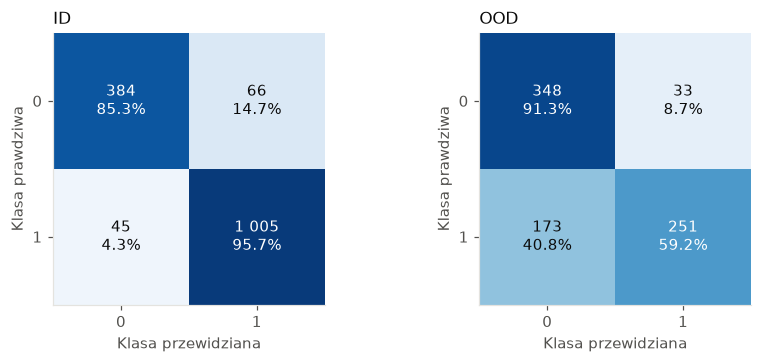

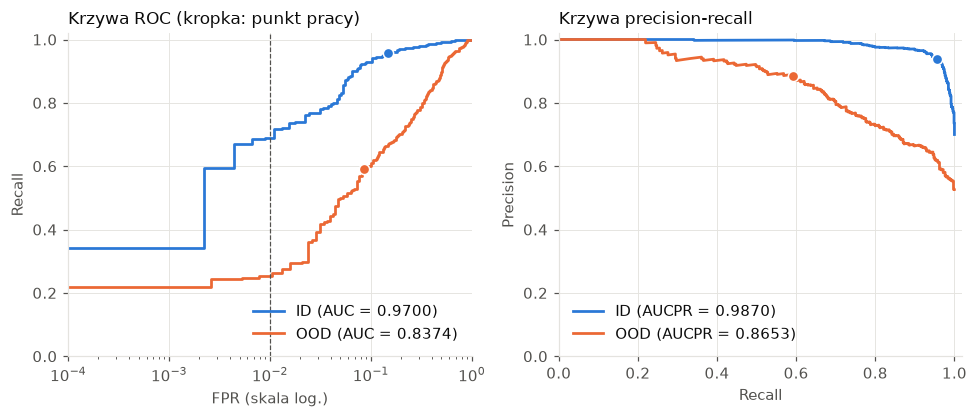

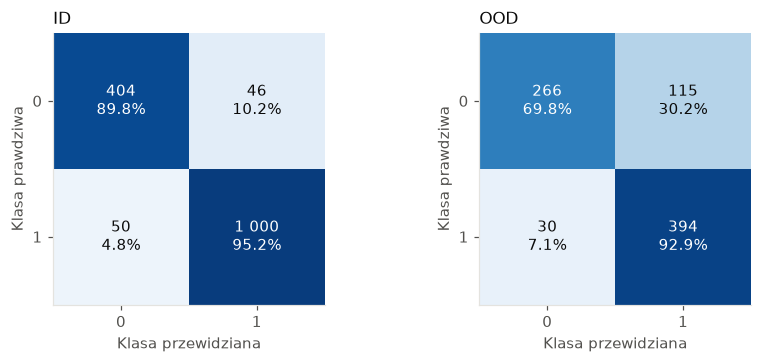

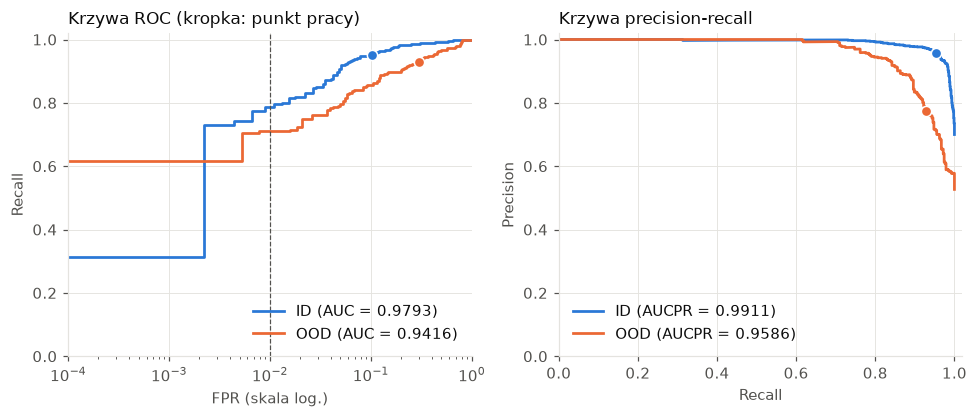

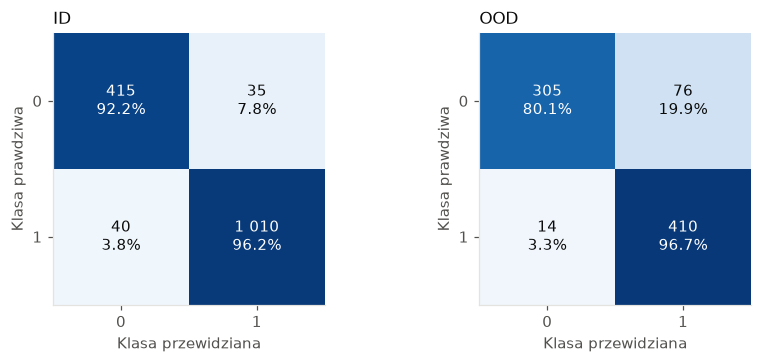

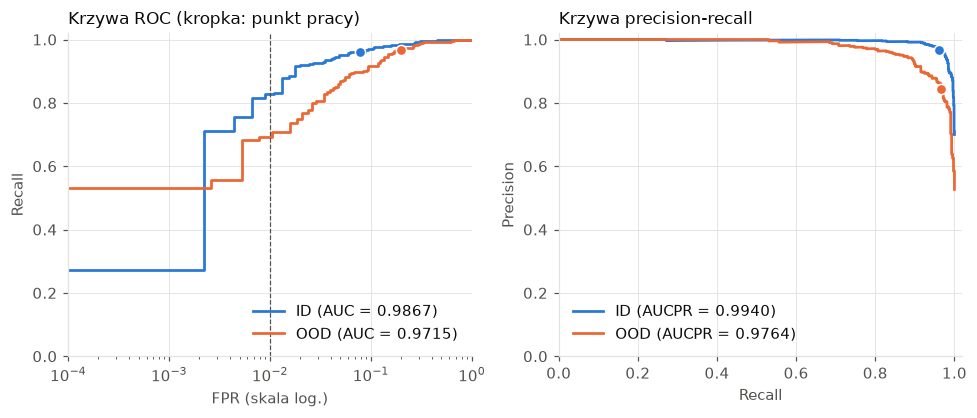

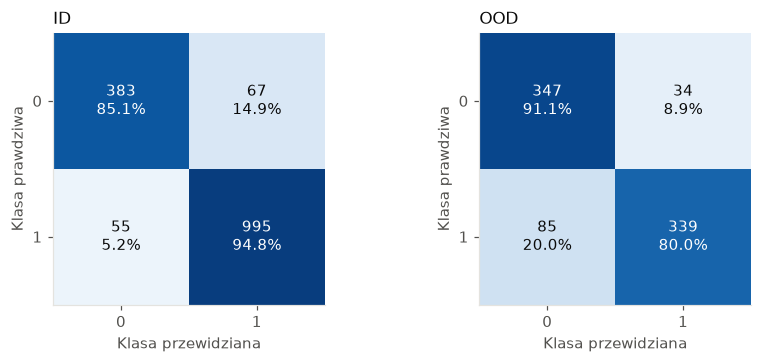

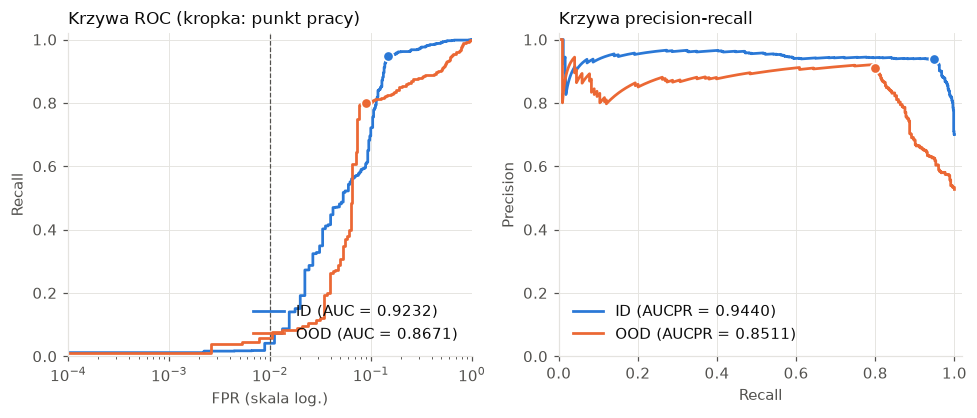

,model,n,nieprawidłowe,s_na_wiadomość,czas_min,tokeny_promptu_śr,znaki_rozumowania_śr
0,qwen2.5:7b,2305,0,0.2035,7.8164,2146.7319,0.0000
1,qwen3.5:9b,2305,0,0.4005,15.3866,2176.9302,0.0000
2,gemma4:12b,2305,0,1.0723,41.1954,2185.4933,0.0000
3,gpt-oss:20b,2305,0,1.5595,59.9109,2162.9202,50.2703


n  positives  accuracy  recall     f1  precision  roc_auc  aucpr    fpr
model       korpus                                                                                
qwen2.5:7b  ID     1500.0000  1050.0000    0.9260  0.9571 0.9477     0.9384   0.9700 0.9870 0.1467
            OOD     805.0000   424.0000    0.7441  0.5920 0.7090     0.8838   0.8374 0.8653 0.0866
qwen3.5:9b  ID     1500.0000  1050.0000    0.9360  0.9524 0.9542     0.9560   0.9793 0.9911 0.1022
            OOD     805.0000   424.0000    0.8199  0.9292 0.8446     0.7741   0.9416 0.9586 0.3018
gemma4:12b  ID     1500.0000  1050.0000    0.9500  0.9619 0.9642     0.9665   0.9867 0.9940 0.0778
            OOD     805.0000   424.0000    0.8882  0.9670 0.9011     0.8436   0.9715 0.9764 0.1995
gpt-oss:20b ID     1500.0000  1050.0000    0.9187  0.9476 0.9422     0.9369   0.9232 0.9440 0.1489
            OOD     805.0000   424.0000    0.8522  0.7995 0.8507     0.9088   0.8671 0.8511 0.0892

In [4]:
predictions = {
    model: mini.merge(pd.read_csv(model_file(model)), on="id", how="inner", validate="one_to_one") for model in MODELS
    if model_file(model).exists()
}
summary_rows, metric_tables, source_tables = [], [], []
for model, frame in predictions.items():
    id_frame, ood_frame = frame[frame.korpus == "ID"], frame[frame.korpus == "OOD"]
    corpus_sets = {"ID": (id_frame[LABEL], id_frame.score.to_numpy()), "OOD": (ood_frame[LABEL], ood_frame.score.to_numpy())}
    metric_tables.append(corpus_metrics(corpus_sets, THRESHOLD).assign(model=model))
    source_sets = {
        name: (frame.loc[frame.source == name, LABEL], frame.loc[frame.source == name, "score"].to_numpy())
        for name in ID_SOURCES + OOD_SOURCES
    }
    source_tables.append(corpus_metrics(source_sets, THRESHOLD).assign(model=model))
    summary_rows.append({
        "model": model, "n": len(frame), "nieprawidłowe": int((~frame.valid).sum()),
        "s_na_wiadomość": frame.seconds.mean(), "czas_min": frame.seconds.sum() / 60,
        "tokeny_promptu_śr": frame.prompt_tokens.mean(), "znaki_rozumowania_śr": frame.thinking_chars.mean(),
    })
    matrices = plot_confusion_matrices(corpus_sets, THRESHOLD, FIGURES / f"confusion_matrices_{model.replace(':', '_')}.pdf")
    for name, matrix in matrices.items():
        matrix.to_csv(TABLES / f"confusion_matrix_{name.lower()}_{model.replace(':', '_')}.csv")
    plot_curves(corpus_sets, THRESHOLD, FIGURES / f"roc_pr_curves_{model.replace(':', '_')}.pdf")

summary = pd.DataFrame(summary_rows)
summary.to_csv(TABLES / "summary.csv", index=False)
metrics = pd.concat(metric_tables).rename_axis("korpus").reset_index().set_index(["model", "korpus"])
metrics.to_csv(TABLES / "metrics.csv")
metrics_by_source = pd.concat(source_tables).rename_axis("source").reset_index().set_index(["model", "source"])
metrics_by_source.to_csv(TABLES / "metrics_by_source.csv")
display(summary)
display(metrics)

## Metryki według źródła

Puste wartości oznaczają metrykę, której nie da się policzyć dla jednej klasy, np. FPR dla Nazario.

In [5]:
display(metrics_by_source)

n  positives  accuracy  recall     f1  precision  roc_auc  aucpr    fpr
model       source                                                                                 
qwen2.5:7b  nazario  300.0000   300.0000    0.8667  0.8667 0.9286     1.0000      NaN    NaN    NaN
            nigerian 300.0000   300.0000    1.0000  1.0000 1.0000     1.0000      NaN    NaN    NaN
            trec05   300.0000   150.0000    0.8867  0.9867 0.8970     0.8222   0.9742 0.9753 0.2133
            trec06   300.0000   150.0000    0.9300  0.9800 0.9333     0.8909   0.9844 0.9823 0.1200
            trec07   300.0000   150.0000    0.9467  1.0000 0.9494     0.9036   0.9910 0.9908 0.1067
            ferb     300.0000   150.0000    0.5900  0.2067 0.3351     0.8857   0.7560 0.7607 0.0267
            kd10000   60.0000    55.0000    1.0000  1.0000 1.0000     1.0000   1.0000 1.0000 0.0000
            nebulon  145.0000    69.0000    0.6552  0.2754 0.4318     1.0000   0.8261 0.8249 0.0000
            zeroday  300.0000   150.0000    0.8900  0.9733 0.8985     0.8343   0.9479 0.9423 0.1933
qwen3.5:9b  nazario  300.0000   300.0000    0.8667  0.8667 0.9286     1.0000      NaN    NaN    NaN
            nigerian 300.0000   300.0000    1.0000  1.0000 1.0000     1.0000      NaN    NaN    NaN
            trec05   300.0000   150.0000    0.9167  0.9733 0.9211     0.8743   0.9760 0.9747 0.1400
            trec06   300.0000   150.0000    0.9433  0.9733 0.9450     0.9182   0.9848 0.9745 0.0867
            trec07   300.0000   150.0000    0.9533  0.9867 0.9548     0.9250   0.9940 0.9939 0.0800
            ferb     300.0000   150.0000    0.8100  0.9400 0.8319     0.7460   0.9494 0.9608 0.3200
            kd10000   60.0000    55.0000    1.0000  1.0000 1.0000     1.0000   1.0000 1.0000 0.0000
            nebulon  145.0000    69.0000    0.7793  0.6957 0.7500     0.8136   0.8703 0.8887 0.1447
            zeroday  300.0000   150.0000    0.8133  1.0000 0.8427     0.7282   0.9983 0.9984 0.3733
gemma4:12b  nazario  300.0000   300.0000    0.8900  0.8900 0.9418     1.0000      NaN    NaN    NaN
            nigerian 300.0000   300.0000    1.0000  1.0000 1.0000     1.0000      NaN    NaN    NaN
            trec05   300.0000   150.0000    0.9300  0.9733 0.9329     0.8957   0.9803 0.9731 0.1133
            trec06   300.0000   150.0000    0.9600  0.9933 0.9613     0.9313   0.9953 0.9954 0.0733
            trec07   300.0000   150.0000    0.9700  0.9867 0.9705     0.9548   0.9964 0.9962 0.0467
            ferb     300.0000   150.0000    0.8967  0.9467 0.9016     0.8606   0.9719 0.9739 0.1533
            kd10000   60.0000    55.0000    1.0000  1.0000 1.0000     1.0000   1.0000 1.0000 0.0000
            nebulon  145.0000    69.0000    0.8759  0.9130 0.8750     0.8400   0.9512 0.9564 0.1579
            zeroday  300.0000   150.0000    0.8633  1.0000 0.8798     0.7853   0.9983 0.9983 0.2733
gpt-oss:20b nazario  300.0000   300.0000    0.8567  0.8567 0.9228     1.0000      NaN    NaN    NaN
            nigerian 300.0000   300.0000    0.9933  0.9933 0.9967     1.0000      NaN    NaN    NaN
            trec05   300.0000   150.0000    0.8733  0.9667 0.8841     0.8146   0.8689 0.8081 0.2200
            trec06   300.0000   150.0000    0.9333  0.9867 0.9367     0.8916   0.9520 0.9168 0.1200
            trec07   300.0000   150.0000    0.9367  0.9800 0.9393     0.9018   0.9528 0.9320 0.1067
            ferb     300.0000   150.0000    0.8067  0.6133 0.7603     1.0000   0.8279 0.8818 0.0000
            kd10000   60.0000    55.0000    1.0000  1.0000 1.0000     1.0000   1.0000 1.0000 0.0000
            nebulon  145.0000    69.0000    0.8000  0.6232 0.7478     0.9348   0.8631 0.8736 0.0395
            zeroday  300.0000   150.0000    0.8933  0.9933 0.9030     0.8278   0.8629 0.7615 0.2067